In [2]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# libreria per grafici 3D
import plotly.graph_objects as go

#libreria utile per coefficienti di lyapunov
from jitcode import jitcode_lyap, y, t

In [4]:
import pyvista as pv

In [5]:
def lorentz(t, y, sigma, roh, beta):
  """""
  funzione di lorentz per generare attrattore,
  t: tempo
  y: condizione iniziale
  ro: parametro ro
  beta: parametro beta

  """""

  X, Y, Z = y

  dX_dt = sigma*(Y-X)
  dY_dt = X*(roh-Z) - Y
  dZ_dt = X*Y - beta*Z

  return [dX_dt, dY_dt, dZ_dt]

In [6]:
X0 = 0.1
Y0 = 0.1
Z0 = 0.1

# condizioni inziali
y0 = [X0, Y0, Z0]

#parametri
sigma = 10
betha = 8/3
roh = 28


t_span = (0, 50)
t_eval = np.linspace(0, 50, 10000)

# sistemat il solver per lorentz e occhio a scrivere le formule
sol = solve_ivp(
    lorentz, t_span, y0, args=(sigma, roh, betha),
    t_eval=t_eval, method='RK45')

#estraiamo le soluzioni dal sistema
x_values = sol.y[0]
y_values = sol.y[1]
z_values = sol.y[2]

#plottiamo il tutto
fig = go.Figure(data=[go.Scatter3d(x=x_values, y=y_values, z=z_values, mode='lines')])

fig.update_layout(title=f"Sistema di Lorentrz con rho  = {roh}", template = "plotly_white")

fig.show(renderer="browser")

let's try with pyvista

In [8]:
sigma = 10.0
rho = 28.0
beta = 8.0 / 3.0
dt = 0.01
n_steps = 8000

points = np.empty((n_steps + 1, 3))
points[0] = (0.0, 1.0, 1.05)

for i in range(n_steps):
    x, y, z = points[i]
    points[i + 1] = (
        x + sigma * (y - x) * dt,
        y + (x * (rho - z) - y) * dt,
        z + (x * y - beta * z) * dt,
    )

trajectory = pv.MultipleLines(points)
trajectory['z'] = points[:, 2]

/tmp/ipykernel_753080/643818486.py:4: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  pl.show(screenshot="lorenz.jpg")


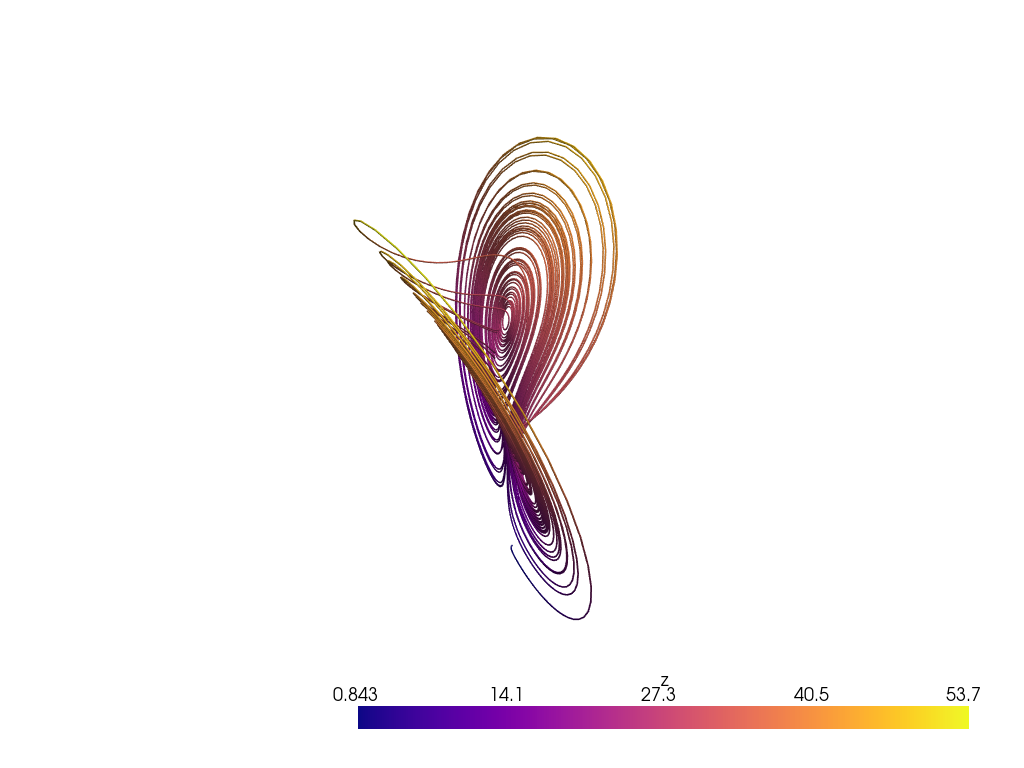

In [9]:
pl = pv.Plotter()
pl.add_mesh(trajectory.tube(radius=0.09), scalars='z', cmap='plasma')

pl.show(screenshot="lorenz.jpg")

## SIR MODEL

In [11]:
def SIR(t, y, beta_sir, gamma):
  """""
  funzione di lorentz per generare attrattore,
  t: tempo
  y: condizione iniziale
  ro: parametro ro
  beta: parametro beta

  """""

  S, I, R = y
  dS_dt = -beta_sir * S * I / N
  dI_dt = beta_sir * S * I / N - gamma * I
  dR_dt = gamma * I
  
  return [dS_dt, dI_dt, dR_dt]

  

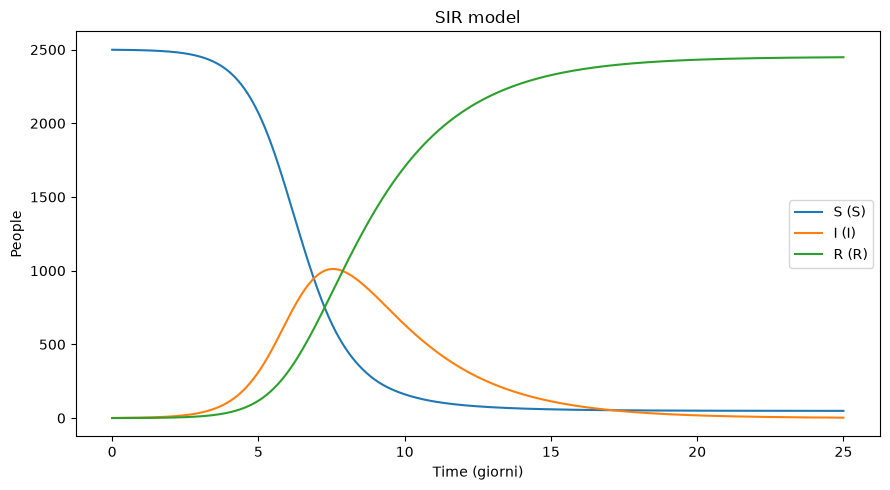

In [26]:
N = 2500
I0 = 1
R0 = 0
S0 = N - I0- R0

# condizioni inziali
y0 = [S0, I0, R0]

#parametri
beta = 0.4 * 4
gamma = 0.1 * 4


t_span = (0, 25)
t_eval = np.linspace(0, 25, 10000)

# sistemat il solver per lorentz e occhio a scrivere le formule
sol = solve_ivp(
    SIR, t_span, y0,
    args=(beta, gamma),
    t_eval=t_eval,
    method="RK45"
)


plt.figure(figsize=(9, 5))
plt.plot(sol.t, sol.y[0], label="S (S)")
plt.plot(sol.t, sol.y[1], label="I (I)")
plt.plot(sol.t, sol.y[2], label="R (R)")

plt.xlabel("Time (giorni)")
plt.ylabel("People")
plt.title("SIR model")
plt.grid(False)
plt.legend()
plt.tight_layout()
plt.show()